# Employee Promotion Prediction

## 1. Project Overview

### Objective

The goal of this project is to predict whether an employee will be promoted based on their performance, experience, training, and other employee-related information.

### Why This Problem?

Employee promotion prediction is a classification problem. The main challenge is that promoted employees are much fewer than non-promoted employees, making this an imbalanced classification problem.

## 2. Import Libraries
We import the libraries required for data manipulation, visualization, preprocessing, model building, and evaluation.

In [1]:
#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Load the Data

In [2]:
#Read Train and Test Data
train = pd.read_csv("/kaggle/input/datasets/shivan118/hranalysis/train.csv")
test = pd.read_csv("/kaggle/input/datasets/shivan118/hranalysis/test.csv")

We first check the number of rows and columns in both datasets.

In [3]:
#Check Dataset Shape
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (54808, 14)
Test shape: (23490, 13)


In [4]:
# check dataset columns
print("\nTrain columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())


Train columns:
['employee_id', 'department', 'region', 'education', 'gender', 'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating', 'length_of_service', 'KPIs_met >80%', 'awards_won?', 'avg_training_score', 'is_promoted']

Test columns:
['employee_id', 'department', 'region', 'education', 'gender', 'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating', 'length_of_service', 'KPIs_met >80%', 'awards_won?', 'avg_training_score']


## Data Understanding

In [5]:
# Data types and non-null values
#This helps us understand the distribution of numerical features.
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  object 
 2   region                54808 non-null  object 
 3   education             52399 non-null  object 
 4   gender                54808 non-null  object 
 5   recruitment_channel   54808 non-null  object 
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  KPIs_met >80%         54808 non-null  int64  
 11  awards_won?           54808 non-null  int64  
 12  avg_training_score    54808 non-null  int64  
 13  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.9+ MB


In [6]:
# Check Missing values

print("Missing values in TRAIN:")
print(train.isnull().sum())

print("\nMissing values in TEST:")
print(test.isnull().sum())

Missing values in TRAIN:
employee_id                0
department                 0
region                     0
education               2409
gender                     0
recruitment_channel        0
no_of_trainings            0
age                        0
previous_year_rating    4124
length_of_service          0
KPIs_met >80%              0
awards_won?                0
avg_training_score         0
is_promoted                0
dtype: int64

Missing values in TEST:
employee_id                0
department                 0
region                     0
education               1034
gender                     0
recruitment_channel        0
no_of_trainings            0
age                        0
previous_year_rating    1812
length_of_service          0
KPIs_met >80%              0
awards_won?                0
avg_training_score         0
dtype: int64


The dataset contains missing values in: **education**, **previous_year_rating**.
We investigate each column before deciding how to handle the missing values.

In [7]:
# Duplicate rows

print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate rows in test:", test.duplicated().sum())


Duplicate rows in train: 0
Duplicate rows in test: 0


In [8]:
# Unique values / number of unique values

for col in train.columns:
    print(f"\n{col}")
    print("Number of unique values:", train[col].nunique())
    print("Sample values:", train[col].unique()[:10])


employee_id
Number of unique values: 54808
Sample values: [65438 65141  7513  2542 48945 58896 20379 16290 73202 28911]

department
Number of unique values: 9
Sample values: ['Sales & Marketing' 'Operations' 'Technology' 'Analytics' 'R&D'
 'Procurement' 'Finance' 'HR' 'Legal']

region
Number of unique values: 34
Sample values: ['region_7' 'region_22' 'region_19' 'region_23' 'region_26' 'region_2'
 'region_20' 'region_34' 'region_1' 'region_4']

education
Number of unique values: 3
Sample values: ["Master's & above" "Bachelor's" nan 'Below Secondary']

gender
Number of unique values: 2
Sample values: ['f' 'm']

recruitment_channel
Number of unique values: 3
Sample values: ['sourcing' 'other' 'referred']

no_of_trainings
Number of unique values: 10
Sample values: [ 1  2  3  4  7  5  6  8 10  9]

age
Number of unique values: 41
Sample values: [35 30 34 39 45 31 33 28 32 49]

previous_year_rating
Number of unique values: 5
Sample values: [ 5.  3.  1.  4. nan  2.]

length_of_service
Number

In [9]:
# Statistical summary of numerical variables

train.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
count,54808.000000,54808.000000,54808.000000,50684.000000,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000
mean,39195.830627,1.253011,34.803915,3.329256,5.865512,0.351974,0.023172,63.386750,0.085170
std,22586.581449,0.609264,7.660169,1.259993,4.265094,0.477590,0.150450,13.371559,0.279137
min,1.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000,0.000000
25%,19669.750000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000,0.000000
50%,39225.500000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000,0.000000
75%,58730.500000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,76.000000,0.000000
max,78298.000000,10.000000,60.000000,5.000000,37.000000,1.000000,1.000000,99.000000,1.000000


In [10]:
# Statistical summary including categorical variables

train.describe(include='object')

,department,region,education,gender,recruitment_channel
count,54808,54808,52399,54808,54808
unique,9,34,3,2,3
top,Sales & Marketing,region_2,Bachelor's,m,other
freq,16840,12343,36669,38496,30446


## Understand the Target variable

In [11]:
# Target distribution

print(train['is_promoted'].value_counts())

print("\nTarget percentage:")
print(train['is_promoted'].value_counts(normalize=True) * 100)

is_promoted
0    50140
1     4668
Name: count, dtype: int64

Target percentage:
is_promoted
0    91.482995
1     8.517005
Name: proportion, dtype: float64


**Only about 8.5% of employees were promoted, while about 91.5% were not promoted.**

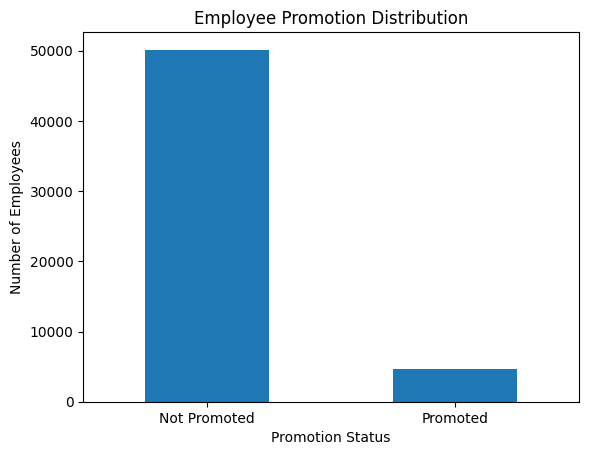

In [12]:
#Plot Employee Promotion Distribution

train['is_promoted'].value_counts().plot(kind='bar')

plt.title('Employee Promotion Distribution')
plt.xlabel('Promotion Status')
plt.ylabel('Number of Employees')
plt.xticks([0, 1], ['Not Promoted', 'Promoted'], rotation=0)
plt.show()

This shows that the target variable is highly imbalanced.

Because of this imbalance, accuracy alone will not be enough to evaluate our models.

## Exploratory Data Analysis

#### Promotion Rate by Department
We compare promotion rates across departments to understand whether promotion outcomes differ across departments.

In [13]:
department_promotion = (
    train.groupby('department')['is_promoted']
    .agg(['count', 'sum', 'mean'])
    .sort_values('mean', ascending=False)
)

department_promotion

,count,sum,mean
department,,,
Technology,7138,768,0.107593
Procurement,7138,688,0.096386
Analytics,5352,512,0.095665
Operations,11348,1023,0.090148
Finance,2536,206,0.081230
Sales & Marketing,16840,1213,0.072031
R&D,999,69,0.069069
HR,2418,136,0.056245
Legal,1039,53,0.051011


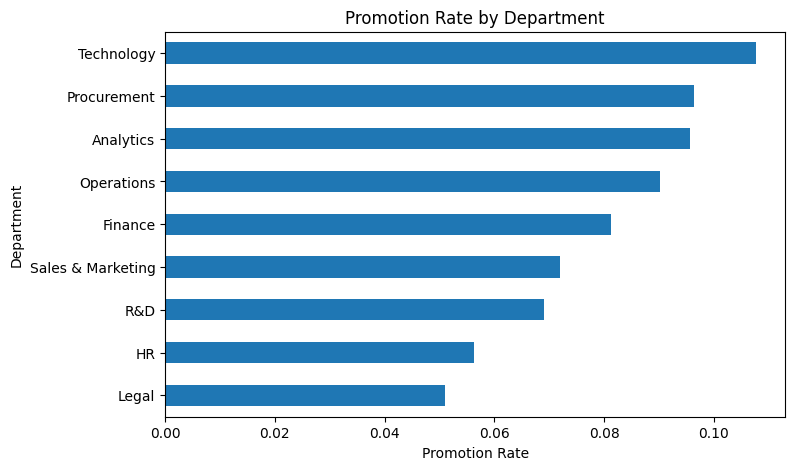

In [14]:
department_promotion['mean'].sort_values().plot(
    kind='barh',
    figsize=(8, 5)
)

plt.title('Promotion Rate by Department')
plt.xlabel('Promotion Rate')
plt.ylabel('Department')
plt.show()

Technology employees had the highest observed promotion rate (10.76%), while Legal had the lowest (5.10%), indicating that promotion patterns vary considerably across departments.

### Promotion Rate by Age Group
We examine promotion rates across different age groups.

In [15]:
# create age group
train['age_group'] = pd.cut(
    train['age'],
    bins=[19, 29, 39, 49, 60],
    labels=['20-29', '30-39', '40-49', '50-60']
)

age_promotion = (
    train.groupby('age_group', observed=True)['is_promoted']
    .agg(['count', 'sum', 'mean'])
    .sort_index()
)

age_promotion

,count,sum,mean
age_group,,,
20-29,14453,1226,0.084827
30-39,28030,2556,0.091188
40-49,8952,664,0.074173
50-60,3373,222,0.065817


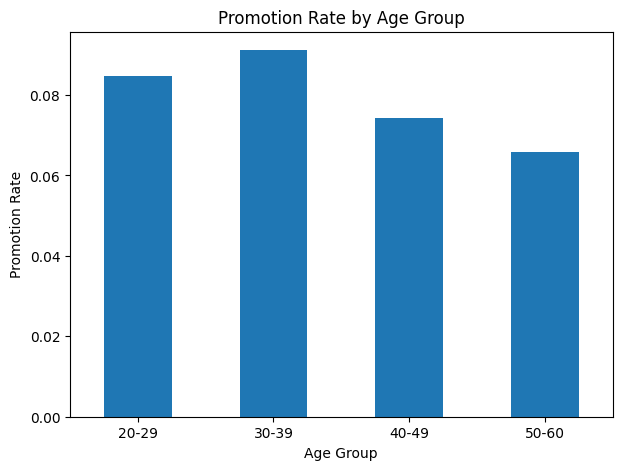

In [16]:
age_promotion['mean'].plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Promotion Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Promotion Rate')
plt.xticks(rotation=0)
plt.show()

Employees aged 30–39 had the highest observed promotion rate, while the 50–60 group had the lowest.

### Promotion Rate by Training

We examine whether promotion rates differ across the number of trainings completed.

In [17]:
training_promotion = (
    train.groupby('no_of_trainings')['is_promoted']
    .agg(['count', 'sum', 'mean'])
    .sort_index()
)

training_promotion

,count,sum,mean
no_of_trainings,,,
1,44378,3910,0.088107
2,7987,605,0.075748
3,1776,122,0.068694
4,468,26,0.055556
5,128,3,0.023438
6,44,2,0.045455
7,12,0,0.000000
8,5,0,0.000000
9,5,0,0.000000


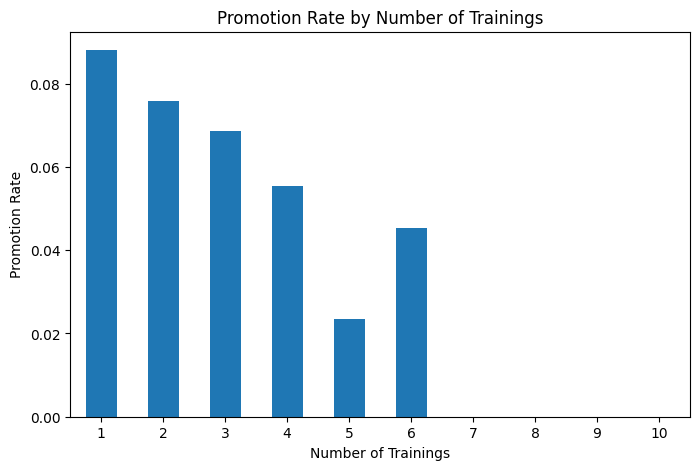

In [18]:
training_promotion['mean'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Promotion Rate by Number of Trainings')
plt.xlabel('Number of Trainings')
plt.ylabel('Promotion Rate')
plt.xticks(rotation=0)
plt.show()

Promotion rates vary across training counts, but the relationship is not consistently increasing or decreasing.

### Promotion Rate by Length of Service 
Rather than looking at all 37 individual values, let's create meaningful groups:

In [19]:
train['service_group'] = pd.cut(
    train['length_of_service'],
    bins=[0, 3, 7, 10, 15, 40],
    labels=['1-3 years', '4-7 years', '8-10 years', '11-15 years', '16+ years']
)

service_promotion = (
    train.groupby('service_group', observed=True)['is_promoted']
    .agg(['count', 'sum', 'mean'])
)

service_promotion

,count,sum,mean
service_group,,,
1-3 years,18264,1581,0.086564
4-7 years,22953,1938,0.084433
8-10 years,7705,702,0.091110
11-15 years,3539,285,0.080531
16+ years,2347,162,0.069024


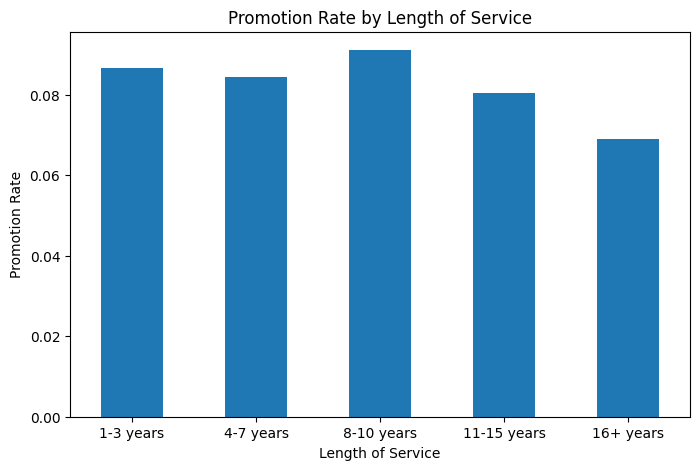

In [20]:
service_promotion['mean'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Promotion Rate by Length of Service')
plt.xlabel('Length of Service')
plt.ylabel('Promotion Rate')
plt.xticks(rotation=0)
plt.show()

Promotion rates vary across service groups without a simple linear pattern.

### Promotion Rate by KPI
This one is especially important.

In [21]:
kpi_promotion = (
    train.groupby('KPIs_met >80%')['is_promoted']
    .agg(['count', 'sum', 'mean'])
)

kpi_promotion


,count,sum,mean
KPIs_met >80%,,,
0,35517,1406,0.039587
1,19291,3262,0.169094


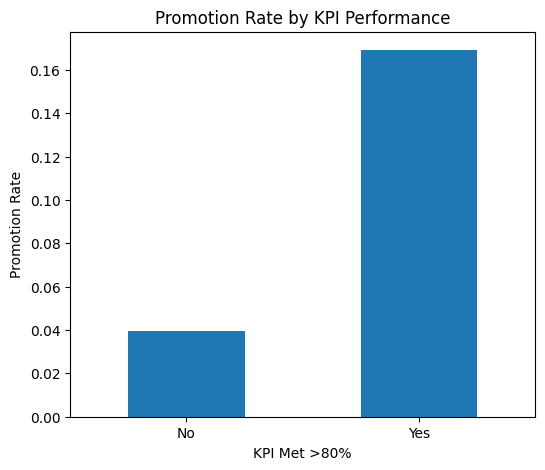

In [22]:
kpi_promotion['mean'].plot(
    kind='bar',
    figsize=(6, 5)
)

plt.title('Promotion Rate by KPI Performance')
plt.xlabel('KPI Met >80%')
plt.ylabel('Promotion Rate')
plt.xticks([0, 1], ['No', 'Yes'], rotation=0)
plt.show()

Employees who met more than 80% of their KPIs had a much higher observed promotion rate.

In [23]:
# Education
education_promotion = (
    train.groupby('education', dropna=False)['is_promoted']
    .agg(['count', 'sum', 'mean'])
    .sort_values('mean', ascending=False)
)

print("EDUCATION")
print(education_promotion)


# Gender
gender_promotion = (
    train.groupby('gender')['is_promoted']
    .agg(['count', 'sum', 'mean'])
    .sort_values('mean', ascending=False)
)

print("\nGENDER")
print(gender_promotion)


# Recruitment Channel
recruitment_promotion = (
    train.groupby('recruitment_channel')['is_promoted']
    .agg(['count', 'sum', 'mean'])
    .sort_values('mean', ascending=False)
)

print("\nRECRUITMENT CHANNEL")
print(recruitment_promotion)


# Awards
awards_promotion = (
    train.groupby('awards_won?')['is_promoted']
    .agg(['count', 'sum', 'mean'])
    .sort_values('mean', ascending=False)
)

print("\nAWARDS")
print(awards_promotion)


EDUCATION
                  count   sum      mean
education                              
Master's & above  14925  1471  0.098559
Below Secondary     805    67  0.083230
Bachelor's        36669  3008  0.082031
NaN                2409   122  0.050643

GENDER
        count   sum      mean
gender                       
f       16312  1467  0.089934
m       38496  3201  0.083151

RECRUITMENT CHANNEL
                     count   sum      mean
recruitment_channel                       
referred              1142   138  0.120841
sourcing             23220  1974  0.085013
other                30446  2556  0.083952

AWARDS
             count   sum      mean
awards_won?                       
1             1270   559  0.440157
0            53538  4109  0.076749


## Previous-year rating

In [24]:
rating_promotion = (
    train.groupby('previous_year_rating', dropna=False)['is_promoted']
    .agg(['count', 'sum', 'mean'])
)

rating_promotion

,count,sum,mean
previous_year_rating,,,
1.0,6223,88,0.014141
2.0,4225,181,0.042840
3.0,18618,1355,0.072779
4.0,9877,784,0.079376
5.0,11741,1921,0.163615
NaN,4124,339,0.082202


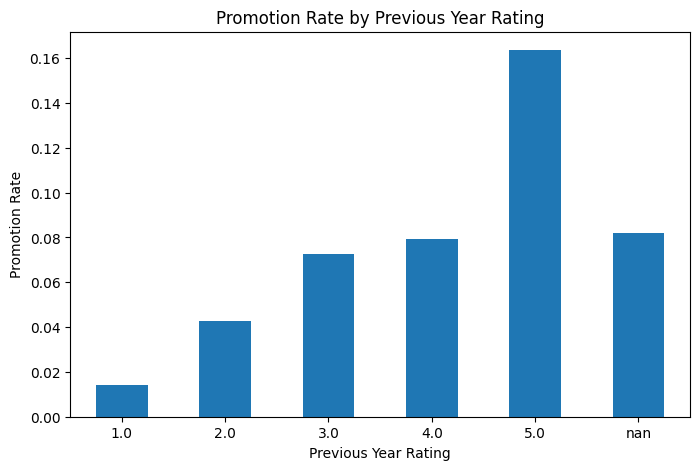

In [25]:
rating_promotion['mean'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Promotion Rate by Previous Year Rating')
plt.xlabel('Previous Year Rating')
plt.ylabel('Promotion Rate')
plt.xticks(rotation=0)
plt.show()

## Data Preprocessing

#### Handling Missing Values in Previous_year_rating


In [26]:
train[train['previous_year_rating'].isna()]['length_of_service'].value_counts()

length_of_service
1    4124
Name: count, dtype: int64

We found all 4,124 employees with a missing previous_year_rating have length_of_service = 1.

This suggests that these employees did not have a previous-year performance rating available.

**Treatment**

We replace missing values with 0.

Here, 0 represents no previous-year rating available, while values from 1–5 represent actual ratings.

In [27]:
train['previous_year_rating'] = train['previous_year_rating'].fillna(0)
test['previous_year_rating'] = test['previous_year_rating'].fillna(0)

#### Handling Missing Values in Education
The available data does not provide enough information to reliably determine an employee's education level.

**Treatment**

We replace missing values with "Unknown" rather than guessing the employee's education.

In [28]:
train['education'] = train['education'].fillna('Unknown')
test['education'] = test['education'].fillna('Unknown')

### Preparing Data for Modeling

**Remove Unnecessary Columns**

employee_id is an identifier and does not provide useful information for predicting promotion.

The EDA-only columns such as age_group and service_group are also removed because we will use the original numerical features for modeling

In [29]:
X = train.drop(['employee_id', 'is_promoted', 'age_group', 'service_group'], axis=1)
y = train['is_promoted']

print(X.shape)
print(y.shape)

(54808, 12)
(54808,)


### Train-Test Split

Now we'll divide the data into training and testing sets.

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (38365, 12)
X_test: (16443, 12)
y_train: (38365,)
y_test: (16443,)


## Why stratify=y?

**Because the target is imbalanced, stratify=y keeps a similar proportion of promoted and non-promoted employees in both training and testing sets.**

### Identify Feature Types

Now we'll separate the columns based on their data type.

In [31]:
categorical_cols = X.select_dtypes(include='object').columns.tolist()
numerical_cols = X.select_dtypes(exclude='object').columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['department', 'region', 'education', 'gender', 'recruitment_channel']
Numerical columns: ['no_of_trainings', 'age', 'previous_year_rating', 'length_of_service', 'KPIs_met >80%', 'awards_won?', 'avg_training_score']


### Feature Preprocessing

 **Why Do We Need Encoding?**
 
Machine learning models work with numerical values, but some features contain categories such as department, education, and gender.

We use **One-Hot Encoding** to convert categorical values into numerical columns.

This avoids creating an artificial order between categories.

 
We use **StandardScaler** to scale numerical features so that variables with different ranges are on a similar scale.

In [32]:
#Create the Preprocessor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

We fit the preprocessing steps only on the training data and then apply them to the test data to avoid data leakage.


In [33]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [34]:
print(X_train_processed.shape)
print(X_test_processed.shape)

(38365, 59)
(16443, 59)


## Modle Building
We first build several baseline classification models and compare their performance.

Because the target is imbalanced, we focus mainly on precision, recall, and F1-score for class 1 (promoted employees).

### Model 1 - Logistic Regression

We'll start with Logistic Regression because:

It's a good baseline model.
It works well for binary classification.
is_promoted has two classes: 0 = Not Promoted, 1 = Promoted.
It gives us a benchmark to compare more complex models against.

In [35]:
# Create the model
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [36]:
# Train the model
log_reg.fit(X_train_processed, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [37]:
# Make predictions
y_pred = log_reg.predict(X_test_processed)

### Model Evaluation

First, let's check the confusion matrix and classification report.

In [38]:
from sklearn.metrics import confusion_matrix, classification_report

# Confusion matrix
print(confusion_matrix(y_test, y_pred))

# Classification report
print(classification_report(y_test, y_pred))

[[14964    79]
 [ 1040   360]]
              precision    recall  f1-score   support

           0       0.94      0.99      0.96     15043
           1       0.82      0.26      0.39      1400

    accuracy                           0.93     16443
   macro avg       0.88      0.63      0.68     16443
weighted avg       0.93      0.93      0.92     16443



### Logistic Regression — Conclusion

The model achieved **93% accuracy**, but accuracy is misleading because the dataset is highly imbalanced.

For employees who were promoted (class 1), the model achieved only **26% recall** and **39% F1-score**, meaning it missed many promoted employees.

Therefore, Logistic Regression is a useful baseline, but we need to improve the model's ability to identify promoted employees.

### Model 2 — Decision Tree

We will use a Decision Tree Classifier as our second model.

A Decision Tree makes predictions by splitting the data based on feature values and creating a series of decision rules.

In [39]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
dt = DecisionTreeClassifier(random_state=42)

# Train the model
dt.fit(X_train_processed, y_train)

# Make predictions
y_pred_dt = dt.predict(X_test_processed)

In [40]:
from sklearn.metrics import confusion_matrix, classification_report

# Confusion matrix
print(confusion_matrix(y_test, y_pred_dt))

# Classification report
print(classification_report(y_test, y_pred_dt))

[[14139   904]
 [  779   621]]
              precision    recall  f1-score   support

           0       0.95      0.94      0.94     15043
           1       0.41      0.44      0.42      1400

    accuracy                           0.90     16443
   macro avg       0.68      0.69      0.68     16443
weighted avg       0.90      0.90      0.90     16443



### Decision Tree — Conclusion

The Decision Tree achieved **90% accuracy**.

For promoted employees (class 1), it achieved **44% recall** and **42% F1-score**, which is better than Logistic Regression.

Although accuracy decreased, the Decision Tree was able to identify more promoted employees. We will compare it with other models to find a better-performing model.

### Model 3 — Random Forest

Random Forest is an ensemble model that combines multiple Decision Trees.

Each tree makes a prediction, and the Random Forest combines their results to make the final prediction.

It can usually provide better and more stable predictions than a single Decision Tree.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf.fit(X_train_processed, y_train)

# Make predictions
y_pred_rf = rf.predict(X_test_processed)

In [ ]:
# Evaluate the model
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

### Random Forest — Conclusion

Random Forest achieved **93% accuracy** with **84% precision** for promoted employees.

However, its recall for promoted employees was only **27%**, meaning it missed many actual promotions.

Compared with the Decision Tree, Random Forest has higher precision but lower recall. We will compare all models and try to improve the prediction of promoted employees.

### Model 4 — Gradient Boosting

Gradient Boosting is an ensemble technique that builds models sequentially.

Each new tree tries to improve the mistakes made by the previous trees.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Create the model
gb = GradientBoostingClassifier(random_state=42)

# Train the model
gb.fit(X_train_processed, y_train)

# Make predictions
y_pred_gb = gb.predict(X_test_processed)

In [ ]:
# Evaluate the model
print(confusion_matrix(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))

### Gradient Boosting — Conclusion

Gradient Boosting achieved **94% accuracy** and **98% precision** for promoted employees.

However, its recall was only **30%**, meaning it still missed many actual promoted employees.

Among the models tested so far, Gradient Boosting gives the best F1-score for class 1. However, we still need to improve recall because identifying promoted employees is important.

### Model 5 — K-Nearest Neighbors

KNN makes predictions based on the most similar observations in the training data.

It looks at the nearest data points and assigns the class based on their majority.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Create the model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train_processed, y_train)

# Make predictions
y_pred_knn = knn.predict(X_test_processed)

In [ ]:
# Evaluate the model
print(confusion_matrix(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

### KNN — Conclusion

KNN achieved **92% accuracy**, but its recall for promoted employees was only **16%**.

This means the model missed many employees who were actually promoted. Therefore, KNN is not suitable for our promotion prediction problem.

### Model Comparison

We trained five classification models and compared their performance using accuracy, precision, recall, and F1-score.

Because the dataset is highly imbalanced, we pay particular attention to the performance of **class 1 (promoted)** rather than relying only on accuracy.

In [ ]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting',
        'KNN'
    ],
    'Accuracy': [0.93, 0.90, 0.93, 0.94, 0.92],
    'Precision (Class 1)': [0.82, 0.41, 0.84, 0.98, 0.52],
    'Recall (Class 1)': [0.26, 0.44, 0.27, 0.30, 0.16],
    'F1-Score (Class 1)': [0.39, 0.42, 0.41, 0.46, 0.24]
})

model_comparison

In [ ]:
model_comparison.style.format({
    'Accuracy': '{:.2%}',
    'Precision (Class 1)': '{:.2%}',
    'Recall (Class 1)': '{:.2%}',
    'F1-Score (Class 1)': '{:.2%}'
})

## Handling Class Imbalance

The target variable is highly imbalanced:

- 91.5% employees were not promoted.
- 8.5% employees were promoted.

Because the minority class is much smaller, the models may favor the majority class.

To improve the model's ability to identify promoted employees, we will test **class weighting**.

`class_weight='balanced'` gives more importance to the minority class during model training.

We will compare the balanced models with their original versions to see whether recall improves.

### Balanced Logistic Regression

In [ ]:
log_reg_balanced = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

log_reg_balanced.fit(X_train_processed, y_train)

y_pred_lr_balanced = log_reg_balanced.predict(X_test_processed)

print(confusion_matrix(y_test, y_pred_lr_balanced))
print(classification_report(y_test, y_pred_lr_balanced))

**Balanced Logistic Regression — Conclusion**

After applying `class_weight='balanced'`, the model's recall for promoted employees increased significantly from **26% to 83%**.

However, precision decreased from **82% to 24%**, and overall accuracy decreased from **93% to 77%**.

This shows the trade-off between precision and recall when handling an imbalanced dataset.

The balanced model identifies many more promoted employees, but it also produces more false positives. Therefore, we need to compare this approach with other balanced models before selecting the final model.

### Balanced Decision Tree

In [ ]:
dt_balanced = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)

dt_balanced.fit(X_train_processed, y_train)

y_pred_dt_balanced = dt_balanced.predict(X_test_processed)

print(confusion_matrix(y_test, y_pred_dt_balanced))
print(classification_report(y_test, y_pred_dt_balanced))

**Balanced Decision Tree — Conclusion**

Applying `class_weight='balanced'` did not significantly improve the Decision Tree.

The recall for promoted employees remained almost unchanged at **43%**, compared with **44%** for the original Decision Tree. The F1-score also remained at **42%**.

Therefore, class weighting does not provide a meaningful improvement for this Decision Tree. We will continue testing class imbalance handling with other models.

### Balanced Random Forest

In [ ]:
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

rf_balanced.fit(X_train_processed, y_train)

y_pred_rf_balanced = rf_balanced.predict(X_test_processed)

print(confusion_matrix(y_test, y_pred_rf_balanced))
print(classification_report(y_test, y_pred_rf_balanced))

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison_balanced = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Logistic Regression (Balanced)',
        'Decision Tree',
        'Decision Tree (Balanced)',
        'Random Forest',
        'Random Forest (Balanced)',
        'Gradient Boosting',
        'KNN'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_lr_balanced),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_dt_balanced),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_balanced),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_knn)
        
    ],
    'Precision (Class 1)': [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_lr_balanced),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt_balanced),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf_balanced),
        precision_score(y_test, y_pred_gb),
        precision_score(y_test, y_pred_knn)
    ],
    'Recall (Class 1)': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_lr_balanced),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_dt_balanced),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_balanced),
        recall_score(y_test, y_pred_gb),
        recall_score(y_test, y_pred_knn)

    ],
    'F1-Score (Class 1)': [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_lr_balanced),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_dt_balanced),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_balanced),
        f1_score(y_test, y_pred_gb),
        f1_score(y_test, y_pred_knn)

    ]
})

comparison_balanced


comparison_balanced.style.format({
    'Accuracy': '{:.2%}',
    'Precision (Class 1)': '{:.2%}',
    'Recall (Class 1)': '{:.2%}',
    'F1-Score (Class 1)': '{:.2%}'
})

## Thereshold tuning

In [ ]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train_sub.shape)
print("Validation data:", X_val.shape)

In [ ]:
X_train_sub_processed = preprocessor.transform(X_train_sub)
X_val_processed = preprocessor.transform(X_val)

print("Training subset:", X_train_sub_processed.shape)
print("Validation data:", X_val_processed.shape)

In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg_balanced_tuning = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

log_reg_balanced_tuning.fit(
    X_train_sub_processed,
    y_train_sub
)

In [ ]:
y_val_prob = log_reg_balanced_tuning.predict_proba(X_val_processed)[:, 1]
y_val_prob[:10]

In [ ]:
y_val_pred_05 = (y_val_prob >= 0.50).astype(int)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_05 = precision_score(y_val, y_val_pred_05)
recall_05 = recall_score(y_val, y_val_pred_05)
f1_05 = f1_score(y_val, y_val_pred_05)

print("Threshold:", 0.50)
print("Precision:", precision_05)
print("Recall:", recall_05)
print("F1-Score:", f1_05)

In [ ]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

results = []

for threshold in thresholds:
    
    y_val_pred = (y_val_prob >= threshold).astype(int)
    
    precision = precision_score(y_val, y_val_pred)
    recall = recall_score(y_val, y_val_pred)
    f1 = f1_score(y_val, y_val_pred)
    
    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

In [ ]:
threshold_results = pd.DataFrame(results)

threshold_results

In [ ]:
best_threshold_row = threshold_results.loc[
    threshold_results['F1-Score'].idxmax()
]

best_threshold_row

In [ ]:
best_threshold = best_threshold_row['Threshold']

print("Best Threshold:", best_threshold)
print("Precision:", best_threshold_row['Precision'])
print("Recall:", best_threshold_row['Recall'])
print("F1-Score:", best_threshold_row['F1-Score'])

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results['Threshold'],
    threshold_results['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_results['Threshold'],
    threshold_results['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_results['Threshold'],
    threshold_results['F1-Score'],
    marker='o',
    label='F1-Score'
)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall and F1 vs Threshold')
plt.legend()
plt.grid()
plt.show()

In [ ]:
 X_test_processed_final = preprocessor.transform(X_test)

y_test_prob = log_reg_balanced_tuning.predict_proba(
    X_test_processed_final
)[:, 1]


In [ ]:
y_test_pred_tuned = (
    y_test_prob >= best_threshold
).astype(int)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_test_pred_tuned)
precision = precision_score(y_test, y_test_pred_tuned)
recall = recall_score(y_test, y_test_pred_tuned)
f1 = f1_score(y_test, y_test_pred_tuned)

print("Threshold:", best_threshold)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_tuned))

**Threshold Tuning – Final Result**

The default classification threshold of 0.5 gave high recall but low precision for the minority class.

We tested thresholds from 0.2 to 0.8 using the validation set. As the threshold increased, precision generally increased while recall decreased.

Among the tested thresholds, **0.7 produced the highest validation F1-score (39.90%)**. Therefore, we selected 0.7 for final evaluation on the untouched test set.

At a threshold of 0.7, the model achieved:

- Accuracy: **85.13%**
- Precision for promoted employees: **30.58%**
- Recall for promoted employees: **58.79%**
- F1-score for promoted employees: **40.23%**

Compared with the balanced Logistic Regression at the default threshold of 0.5, the tuned threshold improved precision and F1-score, but reduced recall.

This demonstrates that the classification threshold should be chosen based on the desired balance between identifying positive cases and avoiding false positives, rather than relying automatically on the default threshold of 0.5.

In [ ]:
final_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Logistic Regression (Balanced)',
        'Decision Tree',
        'Decision Tree (Balanced)',
        'Random Forest',
        'Random Forest (Balanced)',
        'Gradient Boosting',
        'KNN',
        'Balanced Logistic Regression (Threshold 0.7)'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_lr_balanced),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_dt_balanced),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_balanced),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_test_pred_tuned)
    ],
    'Precision (Class 1)': [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_lr_balanced),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt_balanced),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf_balanced),
        precision_score(y_test, y_pred_gb),
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_test_pred_tuned)
    ],
    'Recall (Class 1)': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_lr_balanced),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_dt_balanced),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_balanced),
        recall_score(y_test, y_pred_gb),
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_test_pred_tuned)

    ],
    'F1-Score (Class 1)': [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_lr_balanced),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_dt_balanced),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_balanced),
        f1_score(y_test, y_pred_gb),
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_test_pred_tuned)


    ]
})

final_results


final_results.style.format({
    'Accuracy': '{:.2%}',
    'Precision (Class 1)': '{:.2%}',
    'Recall (Class 1)': '{:.2%}',
    'F1-Score (Class 1)': '{:.2%}'
})

In [ ]:
best_f1_model = final_results.loc[
    final_results['F1-Score (Class 1)'].idxmax()
]

best_f1_model

**Final Model Comparison**

The models were compared using **Accuracy, Precision, Recall, and F1-Score for the promotion class (Class 1)**.

Because the dataset is highly imbalanced, accuracy alone is not enough to select the best model. We therefore focus especially on **Recall and F1-Score for Class 1**.

- **Gradient Boosting** achieved the highest F1-score (46.35%) and the highest precision (97.93%).
- **Balanced Logistic Regression** significantly improved recall to 82.71%, but its precision decreased to 24.36%.
- **Balanced Logistic Regression with a 0.7 threshold** provided a better balance than the default balanced model, with 58.79% recall and 40.23% F1-score.
- **Random Forest (Balanced)** showed only a small improvement over the original Random Forest.
- **KNN** had the lowest F1-score and recall among the tested models.

Overall, **Gradient Boosting performed best when F1-score is the main selection criterion**, while the threshold-tuned Logistic Regression is useful when identifying more potential promoted employees is more important.

### Model Deployment

In [ ]:
import joblib

joblib.dump(gb, 'model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')

print("Model and preprocessor saved successfully.")
